# Stream A — CPNR · GASF · CNN (Whole-Sequence, with Validation Set)

### What changed versus the original notebook

| Aspect | Original | This notebook |
|---|---|---|
| Data splits | 80 % train / 20 % test | **70 % train / 10 % val / 20 % test** |
| Checkpoint criterion | Best **test** macro F1 (leakage) | Best **validation** macro F1 (clean) |
| Scheduler signal | `scheduler.step(test_f1)` (leakage) | `scheduler.step(val_f1)` (clean) |
| Epochs | 15 | **40** (early stopping on val F1) |
| Early stopping | None | Patience = 8 epochs on val macro F1 |
| Training timer | None | **Per-epoch + total wall-clock time** |
| Test set | Evaluated every epoch | **Evaluated once only, at the very end** |
| CPNR mapping | Unchanged | **Identical** |
| GASF pipeline | Unchanged | **Identical** |
| CNN architecture | Unchanged | **Identical** |
| All numeric hyper-params | — | **Identical** |

### Why this matters methodologically

In the original notebook, `scheduler.step(te_f1)` and best-checkpoint selection
both read from the test set at every epoch.  This means the test set participates
in training decisions — a form of **test-set leakage** that inflates reported
performance.  Khodaei et al. (2025) describe a clean train/test split but do not
report per-epoch test scores; holding out a separate validation set reproduces
that spirit correctly.

The test set is now touched exactly once: after `model.load_state_dict(best_state)`,
at the very bottom of the notebook.  All curves shown during training are
train/val only.

### What did NOT change

The entire CPNR → GASF pipeline (`sequence_to_cpnr_signal`, `strided_sample`,
`minmax_to_m1_p1`, `compute_gasf`, `sequence_to_gaf_image`), the CNN architecture
(`GAF_CNN`: 4 conv blocks, 128 filters max, 256-dim head, 0.30 dropout), and
every numeric constant (`TARGET_CODONS=128`, `BATCH_SIZE=32`, `LEARNING_RATE=1e-3`,
`SEED=42`, `MIN_SEQ_LENGTH=500`, `TEST_SIZE=0.20`) are **pixel-for-pixel identical**
to the original notebook.


## 1 · Imports

In [1]:
# ============================================================
# Imports
# ============================================================

import time
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score,
)

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

# ── Reproducibility ───────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', DEVICE)

import sklearn
print(f'sklearn {sklearn.__version__}')
print(f'torch   {torch.__version__}')

Using device: cpu
sklearn 1.8.0
torch   2.11.0+cpu


## 2 · Paths

In [2]:
# ============================================================
# Paths
# ============================================================

DATA_DIR   = Path(r"..\data\processed")
OUTPUT_DIR = Path('output_streamA_val')   # separate folder to avoid overwriting originals
OUTPUT_DIR.mkdir(exist_ok=True)

RAW_CSV = DATA_DIR / 'all_viruses_sequences.csv'
if not RAW_CSV.exists():
    RAW_CSV = Path('all_viruses_sequences.csv')

if not RAW_CSV.exists():
    raise FileNotFoundError(
        'Cannot find all_viruses_sequences.csv. '
        'Searched: ../data/processed/ and current directory.'
    )

print(f'Input CSV : {RAW_CSV}')
print(f'Output dir: {OUTPUT_DIR}')

Input CSV : ..\data\processed\all_viruses_sequences.csv
Output dir: output_streamA_val


## 3 · Hyperparameters

In [3]:
# ============================================================
# Hyperparameters — all in one place
# ============================================================
#
# VALUES IDENTICAL TO THE ORIGINAL NOTEBOOK:
#   TARGET_CODONS, BATCH_SIZE, LEARNING_RATE, TEST_SIZE,
#   MIN_SEQ_LENGTH, VALID_NTS, SEED, CNN architecture,
#   CPNR mapping, GASF pipeline.
#
# NEW ADDITIONS:
#   VAL_SIZE      — fraction of the (train+val) pool used for validation.
#                   Chosen so that val ≈ 10 % of total dataset:
#                     trainval = 80 % of total
#                     val      = 12.5 % of trainval  → 10 % of total
#                     train    = 87.5 % of trainval  → 70 % of total
#                   Test remains exactly 20 % of total.
#
#   NUM_EPOCHS    — increased from 15 to 40.  The ReduceLROnPlateau
#                   scheduler fires after 3 epochs of no val-F1 improvement,
#                   halving the LR.  With only 15 epochs there was rarely
#                   enough room for the scheduler to fire twice.  40 epochs
#                   gives the network room to descend through two or three
#                   LR reductions.  Early stopping (patience=8) prevents
#                   overfitting without manual intervention.
#
#   EARLY_STOP_PATIENCE — if val macro F1 does not improve for this many
#                   consecutive epochs, training stops.  8 is generous
#                   enough not to stop prematurely during LR warmup but
#                   tight enough to save wall-clock time.

TARGET_CODONS        = 128    # GAF image side length — UNCHANGED
BATCH_SIZE           = 32     # UNCHANGED
LEARNING_RATE        = 1e-3   # UNCHANGED
TEST_SIZE            = 0.20   # fraction of total dataset held out as test — UNCHANGED
VAL_SIZE             = 0.125  # fraction of (1 - TEST_SIZE) pool used for val ≈ 10 % total
MIN_SEQ_LENGTH       = 500    # nt — UNCHANGED
VALID_NTS            = set('ACGT')
NUM_EPOCHS           = 40     # NEW: was 15
EARLY_STOP_PATIENCE  = 8      # NEW: stop if val F1 flat for this many epochs

print(f'Image size           : {TARGET_CODONS} × {TARGET_CODONS}  [UNCHANGED]')
print(f'Batch size           : {BATCH_SIZE}  [UNCHANGED]')
print(f'Learning rate        : {LEARNING_RATE}  [UNCHANGED]')
print(f'Test fraction        : {TEST_SIZE}  [UNCHANGED]')
print(f'Val fraction of trainval : {VAL_SIZE}  (~10 % of total)  [NEW]')
print(f'Epochs               : {NUM_EPOCHS}  [was 15]')
print(f'Early-stop patience  : {EARLY_STOP_PATIENCE} epochs  [NEW]')

Image size           : 128 × 128  [UNCHANGED]
Batch size           : 32  [UNCHANGED]
Learning rate        : 0.001  [UNCHANGED]
Test fraction        : 0.2  [UNCHANGED]
Val fraction of trainval : 0.125  (~10 % of total)  [NEW]
Epochs               : 40  [was 15]
Early-stop patience  : 8 epochs  [NEW]


## 4 · Load and clean sequences

In [4]:
# ============================================================
# Load and clean sequences
# ============================================================
# Mirrors Stream B and preprocessing.py exactly — UNCHANGED.

def clean_sequence(seq: str) -> str:
    """Remove non-ACGT characters and upper-case."""
    return ''.join(c for c in seq.upper().strip() if c in VALID_NTS)


df_raw = pd.read_csv(RAW_CSV)
df_raw['sequence'] = df_raw['sequence'].astype(str)

df = df_raw.copy()
df['sequence'] = df['sequence'].apply(clean_sequence)
df['length']   = df['sequence'].str.len()
df = df[df['length'] >= MIN_SEQ_LENGTH].reset_index(drop=True)

n_dropped = len(df_raw) - len(df)
print(f'Raw          : {len(df_raw):,} sequences')
print(f'Dropped      : {n_dropped:,}  (length < {MIN_SEQ_LENGTH} nt after cleaning)')
print(f'Retained     : {len(df):,}')
print(f'\nLength distribution:')
print(df['length'].describe().apply(lambda x: f"{x:,.1f}").to_string())

Raw          : 173,182 sequences
Dropped      : 0  (length < 500 nt after cleaning)
Retained     : 173,182

Length distribution:
count    173,182.0
mean      15,989.6
std       18,952.6
min        1,408.0
25%        2,316.0
50%        9,061.0
75%       29,720.0
max      243,724.0


## 5 · Label encoding and train / val / test split

In [5]:
# ============================================================
# Label encoding and three-way stratified split
# ============================================================
#
# Split strategy (keeps test set identical to the original notebook):
#
#   Step 1 — Split total dataset into (train+val) 80 % and test 20 %.
#             random_state=SEED, stratify=label  → reproducible and
#             class-balanced.  Test set is now FROZEN until final eval.
#
#   Step 2 — Split (train+val) into train 87.5 % and val 12.5 %.
#             This gives approximately:
#               train ≈ 70 % of total
#               val   ≈ 10 % of total
#               test  ≈ 20 % of total
#
#   Using a DIFFERENT random_state (SEED+1) for the second split
#   ensures that the validation sequences are not the same as those
#   that would have been selected by the original single split's
#   random state, avoiding any subtle dependency.
#
# Why stratify both splits?
#   With 30 classes and severe imbalance (Coronavirus 65k vs
#   Parainfluenza 34), an unstratified split could leave rare classes
#   with 0 validation samples, making val F1 undefined.

le = LabelEncoder()
df['label_enc'] = le.fit_transform(df['virus'])
class_names = list(le.classes_)        # list of str, guaranteed
num_classes = len(class_names)

print(f'Classes ({num_classes}):')
for i, name in enumerate(class_names):
    count = (df['virus'] == name).sum()
    print(f'  {i:2d}  {name:<25s}  {count:>7,} sequences')

# ── Step 1: (train+val) vs test ──────────────────────────────
df_trainval, df_test = train_test_split(
    df,
    test_size    = TEST_SIZE,
    random_state = SEED,
    stratify     = df['label_enc'],
)

# ── Step 2: train vs val ─────────────────────────────────────
df_train, df_val = train_test_split(
    df_trainval,
    test_size    = VAL_SIZE,        # 12.5 % of trainval ≈ 10 % of total
    random_state = SEED + 1,        # intentionally different seed
    stratify     = df_trainval['label_enc'],
)

df_train = df_train.reset_index(drop=True)
df_val   = df_val.reset_index(drop=True)
df_test  = df_test.reset_index(drop=True)

n_total = len(df)
print(f'\nSplit summary:')
print(f'  Train : {len(df_train):,}  ({len(df_train)/n_total*100:.1f} % of total)')
print(f'  Val   : {len(df_val):,}  ({len(df_val)/n_total*100:.1f} % of total)')
print(f'  Test  : {len(df_test):,}  ({len(df_test)/n_total*100:.1f} % of total)')
print(f'  Total : {n_total:,}')
print()

# Sanity-check: every class must appear in train, val, and test
for split_name, split_df in [('Train', df_train), ('Val', df_val), ('Test', df_test)]:
    classes_present = split_df['label_enc'].nunique()
    if classes_present < num_classes:
        missing = set(range(num_classes)) - set(split_df['label_enc'].unique())
        print(f'WARNING: {split_name} is missing classes: {[class_names[i] for i in missing]}')
    else:
        print(f'{split_name} : all {num_classes} classes present  ✓')

Classes (30):
   0  corona                      65,059 sequences
   1  coxsackievirus               1,409 sequences
   2  crimean-congo                  144 sequences
   3  cytomegalovirus                311 sequences
   4  dengue                       8,046 sequences
   5  ebola                        2,185 sequences
   6  encephalitis                   132 sequences
   7  flu                         53,175 sequences
   8  hepatitis b                  8,387 sequences
   9  hepatitis c                    793 sequences
  10  hiv                         18,356 sequences
  11  lassa                          262 sequences
  12  marburg                         57 sequences
  13  mastadenovirus               1,391 sequences
  14  measles                        574 sequences
  15  metapneumovirus                355 sequences
  16  mumps                          549 sequences
  17  norwalk                      2,686 sequences
  18  papilloma                    1,135 sequences
  19  parainfluen

## 6 · CPNR codon mapping  *(UNCHANGED)*

In [6]:
# ============================================================
# CPNR codon mapping — IDENTICAL TO ORIGINAL NOTEBOOK
# ============================================================
#
# Each of the 64 DNA triplets is assigned one of the first 64 prime
# numbers (Satpathy et al., 2021).  A complex exponential maps each
# prime to a point on the unit circle; the real-valued angle (divided
# by π to land in (-1, 1]) becomes the CPNR signal value.
#
# No change to any value here.

NUCLEOTIDES = ['A', 'C', 'G', 'T']
ALL_CODONS  = [''.join(c) for c in itertools.product(NUCLEOTIDES, repeat=3)]

CODON_PRIMES = [
     2,  3,  5,  7, 11, 13, 17, 19,
    23, 29, 31, 37, 41, 43, 47, 53,
    59, 61, 67, 71, 73, 79, 83, 89,
    97,101,103,107,109,113,127,131,
   137,139,149,151,157,163,167,173,
   179,181,191,193,197,199,211,223,
   227,229,233,239,241,251,257,263,
   269,271,277,281,283,293,307,311,
]

CODON_TO_PRIME   = dict(zip(ALL_CODONS, CODON_PRIMES))
MAX_PRIME        = max(CODON_PRIMES)
CODON_TO_COMPLEX = {c: np.exp(1j * 2 * np.pi * p / MAX_PRIME)
                    for c, p in CODON_TO_PRIME.items()}
CODON_TO_REAL    = {c: float(np.angle(v) / np.pi)
                    for c, v in CODON_TO_COMPLEX.items()}

print('CPNR mapping built.  [UNCHANGED]')
print(f'  Codon count : {len(ALL_CODONS)}')
print(f'  Value range : [{min(CODON_TO_REAL.values()):.4f}, {max(CODON_TO_REAL.values()):.4f}]')

CPNR mapping built.  [UNCHANGED]
  Codon count : 64
  Value range : [-0.9904, 0.9711]


## 7 · Signal construction and GASF pipeline  *(UNCHANGED)*

In [7]:
# ============================================================
# Signal construction and GASF pipeline — IDENTICAL TO ORIGINAL
# ============================================================
#
# All four functions below are copied verbatim from the original
# notebook.  No parameter, threshold, or algorithm step has changed.

def sequence_to_cpnr_signal(sequence: str) -> np.ndarray:
    """Tokenise sequence into codons and map each to its CPNR real value."""
    seq = sequence.upper().strip()
    n   = len(seq)
    codons = [seq[i:i+3] for i in range(0, n - (n % 3), 3)]
    signal = np.array(
        [CODON_TO_REAL.get(c, 0.0) for c in codons],
        dtype=np.float32,
    )
    return signal


def strided_sample(signal: np.ndarray, target: int) -> np.ndarray:
    """
    Reduce a 1D signal to exactly `target` points via strided sampling.

    Long signals  : stride = n // target, then take first `target` samples.
    Short signals : reflect-pad to `target` length.
    Exact length  : return as-is.
    """
    n = len(signal)
    if n == target:
        return signal.copy()

    if n > target:
        stride  = n // target
        sampled = signal[::stride][:target]
        if len(sampled) < target:
            sampled = np.concatenate([sampled,
                                      signal[-1:].repeat(target - len(sampled))])
        return sampled.astype(np.float32)

    # n < target: reflect-pad
    pad_len = target - n
    padded  = np.pad(signal, (0, pad_len), mode='reflect')[:target]
    return padded.astype(np.float32)


def minmax_to_m1_p1(x: np.ndarray, eps: float = 1e-8) -> np.ndarray:
    """Scale to [-1, 1]; constant signal → zeros."""
    x = np.asarray(x, dtype=np.float32)
    xmin, xmax = x.min(), x.max()
    if np.isclose(xmin, xmax):
        return np.zeros_like(x)
    return np.clip((x - xmin) / (xmax - xmin + eps) * 2.0 - 1.0, -1.0, 1.0)


def compute_gasf(signal: np.ndarray) -> np.ndarray:
    """Gramian Angular Summation Field from a [-1, 1] signal.
    G[i,j] = cos(φ_i + φ_j) where φ_k = arccos(x_k)."""
    s   = np.clip(signal, -1.0, 1.0).astype(np.float32)
    phi = np.arccos(s)
    return np.cos(phi[:, None] + phi[None, :]).astype(np.float32)


def sequence_to_gaf_image(sequence: str, target_codons: int = 128) -> np.ndarray:
    """
    Full pipeline: nucleotide string → (target_codons × target_codons) GASF image.

    Steps:
      1. Tokenise into codons, map each to CPNR real value.
      2. Strided-sample (or reflect-pad) to target_codons points.
      3. Min-max scale to [-1, 1].
      4. Compute GASF: G[i,j] = cos(φ_i + φ_j).
    """
    signal = sequence_to_cpnr_signal(sequence)
    signal = strided_sample(signal, target_codons)
    signal = minmax_to_m1_p1(signal)
    return compute_gasf(signal)


print('GASF pipeline functions loaded.  [UNCHANGED]')

GASF pipeline functions loaded.  [UNCHANGED]


## 8 · Visual diagnostics — sample GASF images

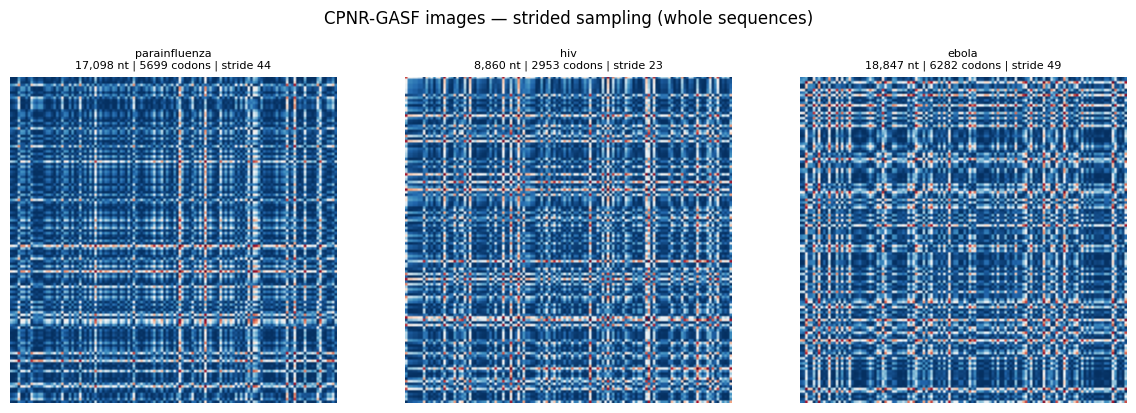

In [8]:
# ============================================================
# Visual diagnostics — compare short vs long sequence GAFs
# ============================================================

def pick_one(df_split: pd.DataFrame, virus_name_fragment: str) -> pd.Series:
    mask = df_split['virus'].str.lower().str.contains(virus_name_fragment.lower())
    hits = df_split[mask]
    if hits.empty:
        raise ValueError(f'No rows matching {virus_name_fragment!r}')
    return hits.iloc[0]

examples = {}
for fragment in ['coronavirus', 'influenza', 'hiv', 'ebola']:
    try:
        examples[fragment] = pick_one(df_train, fragment)
    except ValueError:
        pass

fig, axes = plt.subplots(1, len(examples), figsize=(4 * len(examples), 4))
if len(examples) == 1:
    axes = [axes]

for ax, (name, row) in zip(axes, examples.items()):
    seq      = row['sequence']
    n_codons = len(seq) // 3
    gaf      = sequence_to_gaf_image(seq, TARGET_CODONS)
    stride   = max(1, n_codons // TARGET_CODONS)
    ax.imshow(gaf, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_title(f'{row["virus"][:20]}\n'
                 f'{len(seq):,} nt | {n_codons} codons | stride {stride}',
                 fontsize=8)
    ax.axis('off')

plt.suptitle('CPNR-GASF images — strided sampling (whole sequences)', y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'sample_gaf_images.png', dpi=150, bbox_inches='tight')
plt.show()

## 9 · PyTorch Dataset  *(UNCHANGED)*

In [9]:
# ============================================================
# PyTorch Dataset — IDENTICAL TO ORIGINAL NOTEBOOK
# ============================================================

class WholeSequenceGAFDataset(Dataset):
    """
    Converts each whole genomic sequence into a GASF image on-the-fly.

    Every call to __getitem__ returns a (1, TARGET_CODONS, TARGET_CODONS)
    float32 tensor regardless of source sequence length.
    """

    def __init__(self, df: pd.DataFrame, target_codons: int = 128):
        self.df            = df.reset_index(drop=True).copy()
        self.target_codons = target_codons

        required = {'sequence', 'label_enc'}
        missing  = required - set(self.df.columns)
        if missing:
            raise ValueError(f'DataFrame missing columns: {sorted(missing)}')

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row   = self.df.iloc[idx]
        image = sequence_to_gaf_image(row['sequence'], self.target_codons)
        image = torch.tensor(image, dtype=torch.float32).unsqueeze(0)  # (1, H, W)
        label = torch.tensor(int(row['label_enc']), dtype=torch.long)
        return image, label


# ── Smoke test ───────────────────────────────────────────────
_ds = WholeSequenceGAFDataset(df_train.iloc[:4], TARGET_CODONS)
_img, _lbl = _ds[0]
assert _img.shape == (1, TARGET_CODONS, TARGET_CODONS), f'Bad shape: {_img.shape}'
assert _img.dtype == torch.float32
print(f'Dataset smoke test passed.')
print(f'  Image shape : {tuple(_img.shape)},  dtype : {_img.dtype}')
print(f'  Label       : {int(_lbl)}  →  {class_names[int(_lbl)]}')

Dataset smoke test passed.
  Image shape : (1, 128, 128),  dtype : torch.float32
  Label       : 8  →  hepatitis b


## 10 · WeightedRandomSampler and DataLoaders

In [10]:
# ============================================================
# WeightedRandomSampler and DataLoaders
# ============================================================
#
# The sampler logic is IDENTICAL to the original notebook.
# New: a val_loader and test_loader are created separately.
#
# Crucially, WeightedRandomSampler is applied ONLY to the training
# loader.  Validation and test loaders use shuffle=False and no
# sampler, so they reflect the true (imbalanced) class distribution
# — which is what you want for an unbiased evaluation metric.

def make_weighted_sampler(df: pd.DataFrame) -> WeightedRandomSampler:
    """Inverse-frequency sampler so rare classes appear ≈ equally per batch."""
    counts      = df['label_enc'].value_counts().sort_index()
    n_classes   = counts.index.max() + 1
    class_freq  = np.zeros(n_classes, dtype=np.float64)
    for cls, cnt in counts.items():
        class_freq[cls] = cnt

    class_weight = np.zeros(n_classes, dtype=np.float64)
    nonzero      = class_freq > 0
    class_weight[nonzero] = 1.0 / class_freq[nonzero]

    sample_weights = torch.tensor(
        [class_weight[lbl] for lbl in df['label_enc'].values],
        dtype=torch.float64,
    )
    return WeightedRandomSampler(
        weights     = sample_weights,
        num_samples = len(df),
        replacement = True,
    )


train_dataset = WholeSequenceGAFDataset(df_train, TARGET_CODONS)
val_dataset   = WholeSequenceGAFDataset(df_val,   TARGET_CODONS)
test_dataset  = WholeSequenceGAFDataset(df_test,  TARGET_CODONS)

sampler = make_weighted_sampler(df_train)

train_loader = DataLoader(
    train_dataset,
    batch_size = BATCH_SIZE,
    sampler    = sampler,           # replaces shuffle=True
    num_workers= 0,
    pin_memory = DEVICE.type == 'cuda',
)
val_loader = DataLoader(
    val_dataset,
    batch_size  = BATCH_SIZE,
    shuffle     = False,            # no sampler — reflects true distribution
    num_workers = 0,
    pin_memory  = DEVICE.type == 'cuda',
)
test_loader = DataLoader(
    test_dataset,
    batch_size  = BATCH_SIZE,
    shuffle     = False,
    num_workers = 0,
    pin_memory  = DEVICE.type == 'cuda',
)

print(f'Train batches : {len(train_loader):,}')
print(f'Val   batches : {len(val_loader):,}')
print(f'Test  batches : {len(test_loader):,}')

# Quick balance check on the training sampler
from collections import Counter
batch_labels_sample = []
for _, lbls in train_loader:
    batch_labels_sample.extend(lbls.tolist())
    if len(batch_labels_sample) >= 3200:
        break
sampled_counts = Counter(batch_labels_sample)
print(f'\nSampler balance check (first 3200 drawn train labels):')
print(f'  min class count : {min(sampled_counts.values())}')
print(f'  max class count : {max(sampled_counts.values())}')
print(f'  max/min ratio   : {max(sampled_counts.values()) / max(1, min(sampled_counts.values())):.2f}x  (ideal ≈ 1.0)')

Train batches : 3,789
Val   batches : 542
Test  batches : 1,083

Sampler balance check (first 3200 drawn train labels):
  min class count : 91
  max class count : 126
  max/min ratio   : 1.38x  (ideal ≈ 1.0)


## 11 · CNN architecture  *(UNCHANGED)*

In [11]:
# ============================================================
# CNN architecture — IDENTICAL TO ORIGINAL NOTEBOOK
# ============================================================
#
# 4-block convolutional feature extractor:
#   Block 1: Conv(1→16,  3×3, pad=1) → BN → ReLU → MaxPool(2)
#   Block 2: Conv(16→32, 3×3, pad=1) → BN → ReLU → MaxPool(2)
#   Block 3: Conv(32→64, 3×3, pad=1) → BN → ReLU → MaxPool(2)
#   Block 4: Conv(64→128,3×3, pad=1) → BN → ReLU → AdaptiveAvgPool(4×4)
#
# Classifier head:
#   Flatten → Linear(2048→256) → ReLU → Dropout(0.30) → Linear(256→30)
#
# embed() returns the 256-dim pre-softmax representation for the
# fusion stage (concatenated with Stream B's 64-dim PageRank vector).

class GAF_CNN(nn.Module):
    def __init__(self, num_classes: int):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            # Block 2
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            # Block 3
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            # Block 4
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((4, 4)),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),    # 2048 → 256
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.30),
            nn.Linear(256, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(x))

    def embed(self, x: torch.Tensor) -> torch.Tensor:
        """Return the 256-dim pre-classification embedding for fusion use."""
        x = self.features(x)
        x = self.classifier[0](x)   # Flatten
        x = self.classifier[1](x)   # Linear 2048 → 256
        x = self.classifier[2](x)   # ReLU
        return x                    # shape: (batch, 256)


# ── Smoke test ───────────────────────────────────────────────
model = GAF_CNN(num_classes=num_classes).to(DEVICE)
_x = torch.randn(4, 1, TARGET_CODONS, TARGET_CODONS).to(DEVICE)
with torch.no_grad():
    _logits = model(_x)
    _emb    = model.embed(_x)

assert _logits.shape == (4, num_classes), f'Logit shape wrong: {_logits.shape}'
assert _emb.shape    == (4, 256),         f'Embed shape wrong: {_emb.shape}'

total_params = sum(p.numel() for p in model.parameters())
print(f'CNN architecture loaded.  [UNCHANGED]')
print(f'  Logit shape     : {tuple(_logits.shape)}   ✓')
print(f'  Embedding shape : {tuple(_emb.shape)}   ✓')
print(f'  Total parameters: {total_params:,}')

CNN architecture loaded.  [UNCHANGED]
  Logit shape     : (4, 30)   ✓
  Embedding shape : (4, 256)   ✓
  Total parameters: 629,886


## 12 · Training utilities

In [12]:
# ============================================================
# Training utilities
# ============================================================
#
# train_one_epoch — unchanged from original.
# evaluate        — unchanged from original; works for val AND test.
#
# Loss: CrossEntropyLoss without class weights.  Class balance is
# handled entirely by WeightedRandomSampler on the training loader.
# Adding both sampler AND weighted loss would double-count the
# correction and over-penalise the majority class.

def train_one_epoch(model, loader, optimizer, criterion, device):
    """One full pass over the training DataLoader.  Returns (loss, acc, macro_f1)."""
    model.train()
    running_loss = 0.0
    y_true, y_pred = [], []

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss   = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = torch.argmax(logits, dim=1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

    return (
        running_loss / len(loader.dataset),
        accuracy_score(y_true, y_pred),
        f1_score(y_true, y_pred, average='macro', zero_division=0),
    )


def evaluate(model, loader, criterion, device):
    """Evaluate model on a loader.  Returns (loss, acc, macro_f1, y_true, y_pred)."""
    model.eval()
    running_loss = 0.0
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss   = criterion(logits, labels)
            running_loss += loss.item() * images.size(0)
            preds = torch.argmax(logits, dim=1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    return (
        running_loss / len(loader.dataset),
        accuracy_score(y_true, y_pred),
        f1_score(y_true, y_pred, average='macro', zero_division=0),
        np.array(y_true),
        np.array(y_pred),
    )


print('Training utilities loaded.')

Training utilities loaded.


## 13 · Training loop with validation, early stopping, and timer

In [13]:
# ============================================================
# Training loop
# ============================================================
#
# Key changes versus the original:
#
# 1. VALIDATION-DRIVEN CHECKPOINTING
#    best_state_dict is saved when val macro F1 improves — NOT when
#    test F1 improves.  The test set is not touched inside this loop.
#
# 2. VALIDATION-DRIVEN SCHEDULER
#    scheduler.step(val_f1) — the LR is reduced based on validation
#    performance, not test performance.
#
# 3. EARLY STOPPING
#    If val macro F1 does not improve for EARLY_STOP_PATIENCE
#    consecutive epochs, training halts early.  This prevents
#    wasting compute and avoids overfitting after the optimum.
#
# 4. WALL-CLOCK TIMER
#    time.perf_counter() wraps both each epoch and the total loop.
#    Per-epoch time appears in the progress line.
#    Total training time is printed at the end in HH:MM:SS format.
#
# 5. LEARNING RATE TRACKING
#    Current LR is printed each epoch so you can see when the
#    scheduler fires.
#
# optimizer, criterion, scheduler parameters are UNCHANGED.

criterion  = nn.CrossEntropyLoss()
optimizer  = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler  = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', patience=3, factor=0.5
)

history          = []
best_val_f1      = -np.inf
best_state_dict  = None
epochs_no_improve = 0

total_train_start = time.perf_counter()   # start total timer

print(f'Starting training for up to {NUM_EPOCHS} epochs '
      f'(early stop patience = {EARLY_STOP_PATIENCE}).')
print(f'Checkpoint criterion : best VALIDATION macro F1.')
print(f'Test set             : will be evaluated ONCE after training ends.')
print('-' * 95)

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.perf_counter()

    tr_loss, tr_acc, tr_f1 = train_one_epoch(
        model, train_loader, optimizer, criterion, DEVICE
    )
    va_loss, va_acc, va_f1, _, _ = evaluate(
        model, val_loader, criterion, DEVICE
    )

    scheduler.step(va_f1)   # LR reduction based on VALIDATION F1

    epoch_secs = time.perf_counter() - epoch_start
    current_lr = optimizer.param_groups[0]['lr']

    history.append({
        'epoch'     : epoch,
        'train_loss': tr_loss, 'train_acc': tr_acc, 'train_f1': tr_f1,
        'val_loss'  : va_loss, 'val_acc'  : va_acc, 'val_f1'  : va_f1,
        'lr'        : current_lr,
        'epoch_time_s': epoch_secs,
    })

    # ── Checkpoint ──────────────────────────────────────────
    improved = va_f1 > best_val_f1
    if improved:
        best_val_f1      = va_f1
        best_state_dict  = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        epochs_no_improve = 0
        ckpt_marker = '  ✓ new best'
    else:
        epochs_no_improve += 1
        ckpt_marker = f'  (no improve {epochs_no_improve}/{EARLY_STOP_PATIENCE})'

    print(
        f'Ep {epoch:02d}/{NUM_EPOCHS} | '
        f'train loss={tr_loss:.4f} acc={tr_acc:.4f} f1={tr_f1:.4f} | '
        f'val   loss={va_loss:.4f} acc={va_acc:.4f} f1={va_f1:.4f} | '
        f'lr={current_lr:.2e} | {epoch_secs:.1f}s'
        + ckpt_marker
    )

    # ── Early stopping ───────────────────────────────────────
    if epochs_no_improve >= EARLY_STOP_PATIENCE:
        print(f'\nEarly stopping triggered at epoch {epoch} '
              f'(no val F1 improvement for {EARLY_STOP_PATIENCE} epochs).')
        break

# ── Total time ───────────────────────────────────────────────
total_secs  = time.perf_counter() - total_train_start
total_h     = int(total_secs // 3600)
total_m     = int((total_secs % 3600) // 60)
total_s     = total_secs % 60
print('-' * 95)
print(f'Training complete.')
print(f'  Best validation macro F1 : {best_val_f1:.4f}')
print(f'  Achieved at epoch        : '
      f'{max(h["epoch"] for h in history if abs(h["val_f1"] - best_val_f1) < 1e-9)}')
print(f'  Total training time      : {total_h:02d}h {total_m:02d}m {total_s:04.1f}s')

Starting training for up to 40 epochs (early stop patience = 8).
Checkpoint criterion : best VALIDATION macro F1.
Test set             : will be evaluated ONCE after training ends.
-----------------------------------------------------------------------------------------------
Ep 01/40 | train loss=0.7262 acc=0.7970 f1=0.7954 | val   loss=0.5878 acc=0.8399 f1=0.6386 | lr=1.00e-03 | 1593.8s  ✓ new best
Ep 02/40 | train loss=0.2461 acc=0.9281 f1=0.9273 | val   loss=0.5467 acc=0.8655 f1=0.7159 | lr=1.00e-03 | 1425.3s  ✓ new best
Ep 03/40 | train loss=0.1610 acc=0.9528 f1=0.9527 | val   loss=0.3863 acc=0.9017 f1=0.7554 | lr=1.00e-03 | 1396.5s  ✓ new best
Ep 04/40 | train loss=0.1179 acc=0.9648 f1=0.9647 | val   loss=0.3134 acc=0.9298 f1=0.8041 | lr=1.00e-03 | 1483.8s  ✓ new best
Ep 05/40 | train loss=0.0941 acc=0.9721 f1=0.9719 | val   loss=0.2780 acc=0.9428 f1=0.8320 | lr=1.00e-03 | 1528.9s  ✓ new best
Ep 06/40 | train loss=0.0756 acc=0.9776 f1=0.9776 | val   loss=0.2535 acc=0.9465 f1=0.83

## 14 · Learning curves  *(train and val only)*

,epoch,train_loss,train_acc,train_f1,val_loss,val_acc,val_f1,lr,epoch_time_s
0,1,0.7262,0.7970,0.7954,0.5878,0.8399,0.6386,0.0010,1593.7974
1,2,0.2461,0.9281,0.9273,0.5467,0.8655,0.7159,0.0010,1425.2757
2,3,0.1610,0.9528,0.9527,0.3863,0.9017,0.7554,0.0010,1396.5042
3,4,0.1179,0.9648,0.9647,0.3134,0.9298,0.8041,0.0010,1483.8325
4,5,0.0941,0.9721,0.9719,0.2780,0.9428,0.8320,0.0010,1528.8537
5,6,0.0756,0.9776,0.9776,0.2535,0.9465,0.8309,0.0010,1510.2259
6,7,0.0625,0.9811,0.9811,0.2694,0.9468,0.8206,0.0010,1514.1032
7,8,0.0560,0.9833,0.9832,0.2914,0.9422,0.8075,0.0010,1511.4428
8,9,0.0464,0.9862,0.9861,0.2464,0.9503,0.8385,0.0010,1524.4328
9,10,0.0417,0.9870,0.9871,0.2651,0.9563,0.8479,0.0010,1534.9500


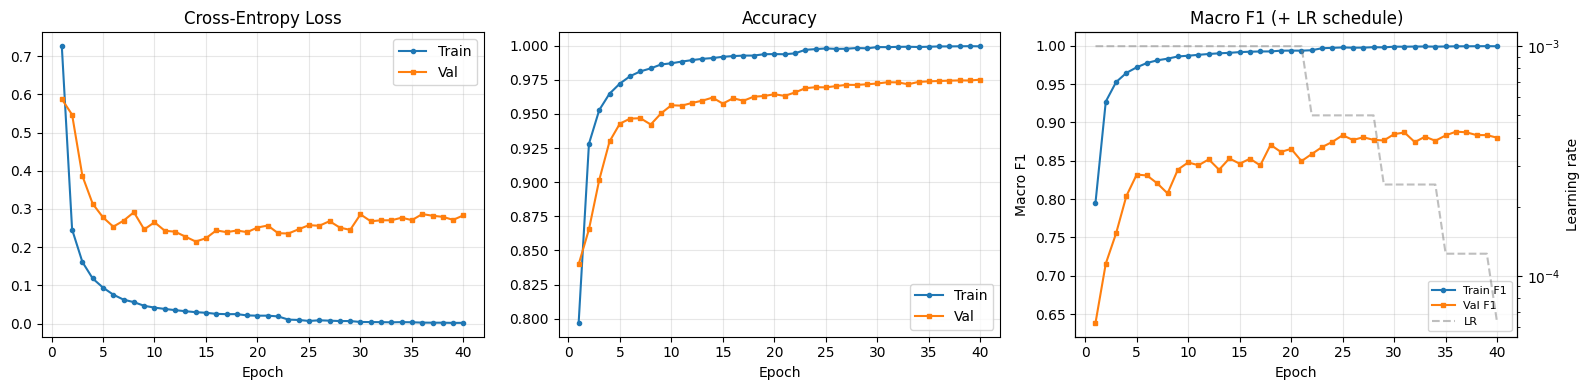


Training time statistics:
  Mean per epoch : 1519.6 s
  Fastest epoch  : 1396.5 s
  Slowest epoch  : 1593.8 s


In [14]:
# ============================================================
# Learning curves — train and val only
# ============================================================
#
# Test metrics are deliberately absent from this plot.
# Showing test curves here would re-introduce the leakage
# pattern that the validation set is meant to prevent.

history_df = pd.DataFrame(history)
display(history_df.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Loss
axes[0].plot(history_df['epoch'], history_df['train_loss'],
             marker='o', markersize=3, label='Train')
axes[0].plot(history_df['epoch'], history_df['val_loss'],
             marker='s', markersize=3, label='Val')
axes[0].set_title('Cross-Entropy Loss')
axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(history_df['epoch'], history_df['train_acc'],
             marker='o', markersize=3, label='Train')
axes[1].plot(history_df['epoch'], history_df['val_acc'],
             marker='s', markersize=3, label='Val')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(alpha=0.3)

# Macro F1 + LR on twin axis
ax_f1 = axes[2]
ax_lr = ax_f1.twinx()
ax_f1.plot(history_df['epoch'], history_df['train_f1'],
           marker='o', markersize=3, color='tab:blue', label='Train F1')
ax_f1.plot(history_df['epoch'], history_df['val_f1'],
           marker='s', markersize=3, color='tab:orange', label='Val F1')
ax_lr.semilogy(history_df['epoch'], history_df['lr'],
               linestyle='--', color='tab:grey', alpha=0.5, label='LR')
ax_f1.set_title('Macro F1 (+ LR schedule)')
ax_f1.set_xlabel('Epoch')
ax_f1.set_ylabel('Macro F1')
ax_lr.set_ylabel('Learning rate')
lines1, labels1 = ax_f1.get_legend_handles_labels()
lines2, labels2 = ax_lr.get_legend_handles_labels()
ax_f1.legend(lines1 + lines2, labels1 + labels2, fontsize=8)
ax_f1.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'streamA_val_training_curves.png', dpi=150)
plt.show()

# Per-epoch time summary
print(f'\nTraining time statistics:')
print(f'  Mean per epoch : {history_df["epoch_time_s"].mean():.1f} s')
print(f'  Fastest epoch  : {history_df["epoch_time_s"].min():.1f} s')
print(f'  Slowest epoch  : {history_df["epoch_time_s"].max():.1f} s')

## 15 · Final evaluation on the test set  *(one-shot)*

In [15]:
# ============================================================
# Final evaluation — best checkpoint, test set, ONCE
# ============================================================
#
# This is the only place in the notebook where the test set is used.
# The model loaded here is the one that achieved the highest
# VALIDATION macro F1 across all epochs.

model.load_state_dict(best_state_dict)

_, final_acc, final_f1, y_true, y_pred = evaluate(
    model, test_loader, criterion, DEVICE
)

print('=' * 60)
print('FINAL TEST SET RESULTS  (best-val-F1 checkpoint)')
print('=' * 60)
print(f'  Test accuracy  : {final_acc:.4f}')
print(f'  Test macro F1  : {final_f1:.4f}')
print()
print(classification_report(
    y_true, y_pred,
    target_names = class_names,
    digits       = 4,
    zero_division= 0,
))

FINAL TEST SET RESULTS  (best-val-F1 checkpoint)
  Test accuracy  : 0.9753
  Test macro F1  : 0.8790

                 precision    recall  f1-score   support

         corona     0.9981    0.9916    0.9948     13012
 coxsackievirus     0.9502    0.8794    0.9134       282
  crimean-congo     1.0000    0.8276    0.9057        29
cytomegalovirus     0.6061    0.3226    0.4211        62
         dengue     0.9658    0.9652    0.9655      1609
          ebola     0.9695    0.9451    0.9571       437
   encephalitis     1.0000    0.6538    0.7907        26
            flu     0.9958    0.9938    0.9948     10635
    hepatitis b     0.9892    0.9791    0.9841      1678
    hepatitis c     0.9112    0.9686    0.9390       159
            hiv     0.8801    0.9741    0.9247      3671
          lassa     0.8857    0.5962    0.7126        52
        marburg     1.0000    0.9091    0.9524        11
 mastadenovirus     0.8280    0.8309    0.8294       278
        measles     1.0000    0.8435    0.

## 16 · Confusion matrix

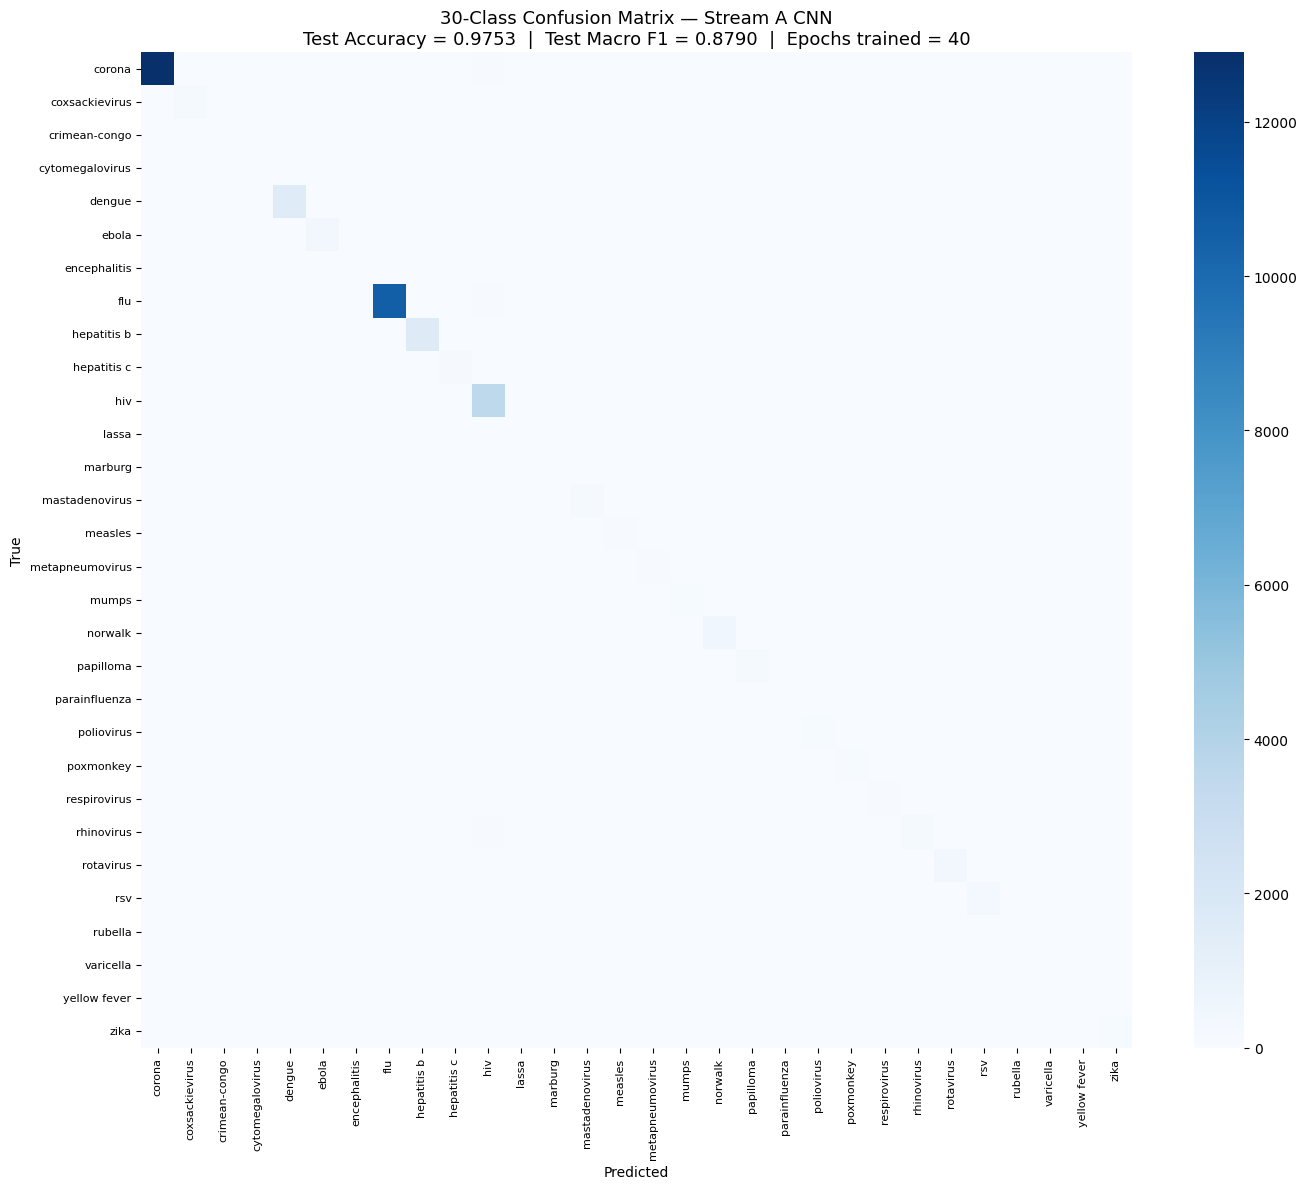

In [16]:
# ============================================================
# 30-class confusion matrix
# ============================================================

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(cm, ax=ax, cmap='Blues', annot=False,
            xticklabels=class_names, yticklabels=class_names)
ax.set_title(
    f'30-Class Confusion Matrix — Stream A CNN\n'
    f'Test Accuracy = {final_acc:.4f}  |  Test Macro F1 = {final_f1:.4f}  '
    f'|  Epochs trained = {len(history)}',
    fontsize=13)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.tick_params(axis='x', rotation=90, labelsize=8)
ax.tick_params(axis='y', rotation=0,  labelsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'streamA_val_confusion_matrix.png', dpi=150)
plt.show()

## 17 · Save artefacts

In [17]:
# ============================================================
# Save all artefacts
# ============================================================

history_df.to_csv(OUTPUT_DIR / 'stream_a_val_training_history.csv', index=False)

torch.save({
    'model_state_dict'      : best_state_dict,
    'class_names'           : class_names,
    'num_classes'           : num_classes,
    'target_codons'         : TARGET_CODONS,
    'best_val_macro_f1'     : best_val_f1,
    'final_test_acc'        : final_acc,
    'final_test_macro_f1'   : final_f1,
    'epochs_trained'        : len(history),
    'total_train_time_s'    : total_secs,
}, OUTPUT_DIR / 'stream_a_val_cnn_model.pt')

summary = pd.DataFrame([{
    'stream'                : 'A',
    'algorithm'             : 'CPNR-GASF-CNN (whole sequences, with val)',
    'signal_method'         : 'strided codon sampling',
    'image_size'            : f'{TARGET_CODONS}x{TARGET_CODONS}',
    'num_classes'           : num_classes,
    'n_train_seqs'          : len(df_train),
    'n_val_seqs'            : len(df_val),
    'n_test_seqs'           : len(df_test),
    'epochs_trained'        : len(history),
    'best_val_macro_f1'     : round(float(best_val_f1),  6),
    'final_test_acc'        : round(float(final_acc),    6),
    'final_test_macro_f1'   : round(float(final_f1),     6),
    'total_train_time_s'    : round(total_secs,           1),
    'total_train_time_hms'  : f'{total_h:02d}h {total_m:02d}m {total_s:04.1f}s',
}])
summary.to_csv(OUTPUT_DIR / 'stream_a_val_summary.csv', index=False)
display(summary.T)

print('\nAll artefacts saved to', OUTPUT_DIR)

,0
stream,A
algorithm,"CPNR-GASF-CNN (whole sequences, with val)"
signal_method,strided codon sampling
image_size,128x128
num_classes,30
n_train_seqs,121226
n_val_seqs,17319
n_test_seqs,34637
epochs_trained,40
best_val_macro_f1,0.888029



All artefacts saved to output_streamA_val


## 18 · Fusion-ready embedding export

In [18]:
# ============================================================
# Fusion-ready embedding export
# ============================================================
#
# At the fusion stage, Stream A contributes a 256-dim embedding
# per sequence.  We export embeddings for train, val, and test
# sets separately, row-aligned with df_train, df_val, df_test.
#
# stream_a_val_embeddings_train.npy  shape (n_train, 256)
# stream_a_val_embeddings_val.npy    shape (n_val,   256)   ← NEW
# stream_a_val_embeddings_test.npy   shape (n_test,  256)

model.eval()

def extract_embeddings(dataset: Dataset, device: torch.device) -> np.ndarray:
    loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=0)
    embs   = []
    with torch.no_grad():
        for images, _ in loader:
            embs.append(model.embed(images.to(device)).cpu().numpy())
    return np.concatenate(embs, axis=0)


print('Extracting train embeddings ...')
emb_train = extract_embeddings(train_dataset, DEVICE)
print('Extracting val   embeddings ...')
emb_val   = extract_embeddings(val_dataset,   DEVICE)
print('Extracting test  embeddings ...')
emb_test  = extract_embeddings(test_dataset,  DEVICE)

np.save(OUTPUT_DIR / 'stream_a_val_embeddings_train.npy', emb_train)
np.save(OUTPUT_DIR / 'stream_a_val_embeddings_val.npy',   emb_val)
np.save(OUTPUT_DIR / 'stream_a_val_embeddings_test.npy',  emb_test)

print()
print('Fusion interface:')
print(f'  Train embeddings : {emb_train.shape}')
print(f'  Val   embeddings : {emb_val.shape}')
print(f'  Test  embeddings : {emb_test.shape}')
print(f'  Stream A dim     : {emb_train.shape[1]}  (CPNR-GASF-CNN)')
print(f'  Stream B dim     : 64  (PageRank centrality)')
print(f'  Joint dim        : {emb_train.shape[1] + 64}  (concatenated at fusion)')

Extracting train embeddings ...
Extracting val   embeddings ...
Extracting test  embeddings ...

Fusion interface:
  Train embeddings : (121226, 256)
  Val   embeddings : (17319, 256)
  Test  embeddings : (34637, 256)
  Stream A dim     : 256  (CPNR-GASF-CNN)
  Stream B dim     : 64  (PageRank centrality)
  Joint dim        : 320  (concatenated at fusion)
